# 1.П1. ЦПТ. Дельта-метод. Построение оценок и доверительных интервалов

> **Модуль:** A/B тестирование · **Блок:** практический · **Время:** 1.5 ч · **Опирается на:** 1.01, 1.02

В лекции мы уже упоминали «практическую» проблему A/B-аналитики: метрику посчитать обычно легко, а вот **правильно оценить её неопределённость** — не всегда. Когда метрика устроена как среднее (value-метрика), всё прозрачно: есть ЦПТ, есть стандартная ошибка, есть привычный доверительный интервал. Но реальный мир быстро подсовывает метрики посложнее: **отношения** (средний чек, CTR, trips per hour), **uplift'ы** (доля, делённая на долю), **перцентили** (95-й, 99-й), а иногда ещё и данные на уровне событий, где внутри пользователя всё зависимо. Тут «взять дисперсию как у среднего» уже нельзя: метрика становится **нелинейной** функцией от случайных величин, и наивные формулы уверенно рисуют слишком узкие интервалы, создавая ложную уверенность в эффекте.

**Что сделаем на практике**

1. Посмотрим, как и когда «включается» ЦПТ — в том числе на реальной выручке с тяжёлым хвостом.
2. Вспомним дельта-метод и выведем с его помощью дисперсии для uplift и ratio-метрик.
3. Реализуем доверительные интервалы для value-, ratio- и перцентильных метрик.
4. **Проверим их честность**: на реальных данных посчитаем, как часто 95% ДИ действительно накрывает истинное значение, и увидим, во сколько раз ошибаются наивные подходы.

**Как работать с ноутбуком**

* Ячейки с заданиями помечены **«Задание»**: впишите свой код вместо `raise NotImplementedError`.
* Сразу под заданием лежит свёрнутая ячейка **«Решение»**. В Colab она раскрывается кликом по заголовку, в Jupyter / VS Code — кликом по свёрнутой ячейке.
* После решения идёт ячейка **«Проверка»** — она использует вашу функцию.
* Если запустить ноутбук целиком («Run all»), решения перезапишут ваши функции — так ноутбук всегда исполняется до конца. Чтобы проверить свой код, запускайте ячейку задания и сразу ячейку проверки, пропуская решение.

| Блок | Время |
|---|---|
| 0. Данные | 5 мин |
| 1. ЦПТ | 20 мин |
| 2. Дельта-метод | 15 мин |
| 3–4. Value-метрики | 20 мин |
| 5. Ratio-метрики | 15 мин |
| 6. Перцентили | 15 мин |

## 0. Подготовка

### Библиотеки

In [1]:
import math
import hashlib
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["font.size"] = 11

### Данные: Online Retail II

[Online Retail II](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci) — открытый датасет транзакций британского интернет-магазина подарков за 2009–2011 гг. (оригинал — [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii), автор Daqing Chen, лицензия CC BY 4.0). Каждая строка — позиция в заказе:

| Колонка | Смысл |
|---|---|
| `Invoice` | номер заказа (начинается с `C` — отмена) |
| `Quantity`, `Price` | количество и цена позиции |
| `Customer ID` | идентификатор клиента |
| `InvoiceDate`, `Country`, ... | остальное нам не понадобится |

Скачиваем через `kagglehub` — для публичных датасетов авторизация на Kaggle не нужна.

In [2]:
try:
    import kagglehub
except ImportError:
    %pip install -q kagglehub
    import kagglehub

path = kagglehub.dataset_download("mashlyn/online-retail-ii-uci")
raw = pd.read_csv(f"{path}/online_retail_II.csv",
                  usecols=["Invoice", "Quantity", "Price", "Customer ID"],
                  dtype={"Invoice": str})
print(raw.shape)
raw.head()

(1067371, 4)


,Invoice,Quantity,Price,Customer ID
0,489434,12,6.95,13085.0
1,489434,12,6.75,13085.0
2,489434,12,6.75,13085.0
3,489434,48,2.10,13085.0
4,489434,24,1.25,13085.0


Собираем два уровня данных:

* **события** — заказы: `orders` (клиент, заказ, сумма заказа);
* **пользователи** — клиенты: `users` (выручка за период, число заказов, был ли повторный заказ).

Отбрасываем отмены, позиции без клиента и с неположительными количеством или ценой.

In [3]:
clean = raw[raw["Customer ID"].notna()
            & ~raw["Invoice"].str.startswith("C")
            & (raw["Quantity"] > 0) & (raw["Price"] > 0)].copy()
clean["revenue"] = clean["Quantity"] * clean["Price"]

orders = (clean.groupby(["Customer ID", "Invoice"], as_index=False)["revenue"].sum()
               .rename(columns={"Customer ID": "user_id", "revenue": "order_value"})
               .sort_values("user_id", kind="stable").reset_index(drop=True))

users = (orders.groupby("user_id")
               .agg(revenue=("order_value", "sum"), n_orders=("order_value", "size"))
               .reset_index())
users["repeat"] = (users["n_orders"] > 1).astype(float)

print(f"клиентов: {len(users)}, заказов: {len(orders)}")
users.describe(percentiles=[.5, .9, .99]).round(2)

клиентов: 5878, заказов: 36969


,user_id,revenue,n_orders,repeat
count,5878.00,5878.00,5878.00,5878.00
mean,15315.31,3018.62,6.29,0.72
std,1715.57,14737.73,13.01,0.45
min,12346.00,2.95,1.00,0.00
50%,15314.50,898.92,3.00,1.00
90%,17696.30,5595.37,13.00,1.00
99%,18228.23,29730.42,46.00,1.00
max,18287.00,608821.65,398.00,1.00


### Датасет как генеральная совокупность

Главный инструмент этой практики — **проверка покрытия**: 95% ДИ честный, если в 95% повторений эксперимента он накрывает истинное значение метрики. На реальном A/B-тесте истину мы не знаем, поэтому сделаем так:

1. Объявим всех клиентов датасета **генеральной совокупностью** — для неё мы знаем «истинные» значения любых метрик.
2. «Эксперимент» = случайная выборка `n` клиентов **с возвращением** в контроль и столько же в тест. Если ничего не менять — это A/A-тест с истинным эффектом 0. Если умножить выручку теста на 1.05 — это A/B-тест с истинным uplift ровно +5%.
3. Повторяем эксперимент `R` раз и считаем долю ДИ, накрывших истину.

Ниже — служебные функции для этого. Разбираться в их устройстве не обязательно.

In [4]:
Z95 = NormalDist().inv_cdf(0.975)
rng = np.random.default_rng(2026)

N_USERS = len(users)
REV = users["revenue"].to_numpy()            # выручка клиента (value-метрика)
REPEAT = users["repeat"].to_numpy()          # был ли повторный заказ (конверсия)
N_ORD = users["n_orders"].to_numpy(float)    # число заказов клиента
ORDER_VALUES = orders["order_value"].to_numpy()
_OFFSETS = np.r_[0, np.cumsum(users["n_orders"].to_numpy())]


def sample_users(n):
    """Индексы n клиентов, выбранных с возвращением."""
    return rng.integers(0, N_USERS, size=n)


def orders_of(idx):
    """Заказы выбранных клиентов: (суммы заказов, номер клиента в выборке для каждого заказа)."""
    lens = N_ORD[idx].astype(int)
    starts = _OFFSETS[idx]
    pos = np.repeat(starts - np.r_[0, np.cumsum(lens)[:-1]], lens) + np.arange(lens.sum())
    return ORDER_VALUES[pos], np.repeat(np.arange(len(idx)), lens)


def coverage(experiment, R=1000):
    """Доля повторений, в которых ДИ накрыл истину. experiment() -> (lo, hi, truth)."""
    hits = 0
    for _ in range(R):
        lo, hi, truth = experiment()
        hits += lo <= truth <= hi
    return hits / R


TRUE_AOV = REV.sum() / N_ORD.sum()   # истинный средний чек
print(f"Средняя выручка клиента: {REV.mean():.1f}")
print(f"Доля клиентов с повторным заказом: {REPEAT.mean():.3f}")
print(f"Средний чек (выручка / заказы): {TRUE_AOV:.1f}")

Средняя выручка клиента: 3018.6
Доля клиентов с повторным заказом: 0.724
Средний чек (выручка / заказы): 480.0


## 1. Центральная предельная теорема

Предположим, мы измеряем в A/B-тесте две метрики: конверсию $C$ (доля пользователей, совершивших действие) и выручку на пользователя $T$. Нулевые гипотезы — «A и B не отличаются»:

$$
H_0^{\text{conv}}:\ C_A = C_B, \qquad H_0^{\text{rev}}:\ T_A = T_B.
$$

Обе величины — **средние**: конверсия — среднее бернуллиевских 0/1, выручка — среднее поюзерных трат. Популярные $z$- и $t$-тесты опираются на то, что **нормально распределены выборочные средние, а не сами данные**. Сами данные почти никогда не нормальны: конверсии — это нули и единицы, а выручка обычно имеет длинный правый хвост. Но при достаточно большой выборке распределение выборочного среднего приближается к нормальному — это гарантирует **центральная предельная теорема (ЦПТ)**.

Классическая формулировка: пусть $X_1, \dots, X_n$ — независимые одинаково распределённые случайные величины с конечными математическим ожиданием $\mu$ и дисперсией $\sigma^2$. Тогда

$$
\frac{\sum_{i=1}^n X_i - \mu n}{\sigma \sqrt n} \xrightarrow{d} \mathcal N(0,1), \quad n \to \infty,
\qquad\text{т.е.}\qquad
\bar X_n \approx \mathcal N\!\left(\mu,\ \frac{\sigma^2}{n}\right).
$$

Проверим это симуляцией Монте-Карло: берём выборку размера $n$ из некоторого распределения, считаем среднее, повторяем много раз и сравниваем гистограмму средних с предсказанием ЦПТ $\mathcal N(\mu, \sigma^2/n)$ (красная линия). Помимо «удобных» распределений добавим два **тяжелохвостых** — логнормальное и Парето: именно так обычно выглядят выручка и чеки.

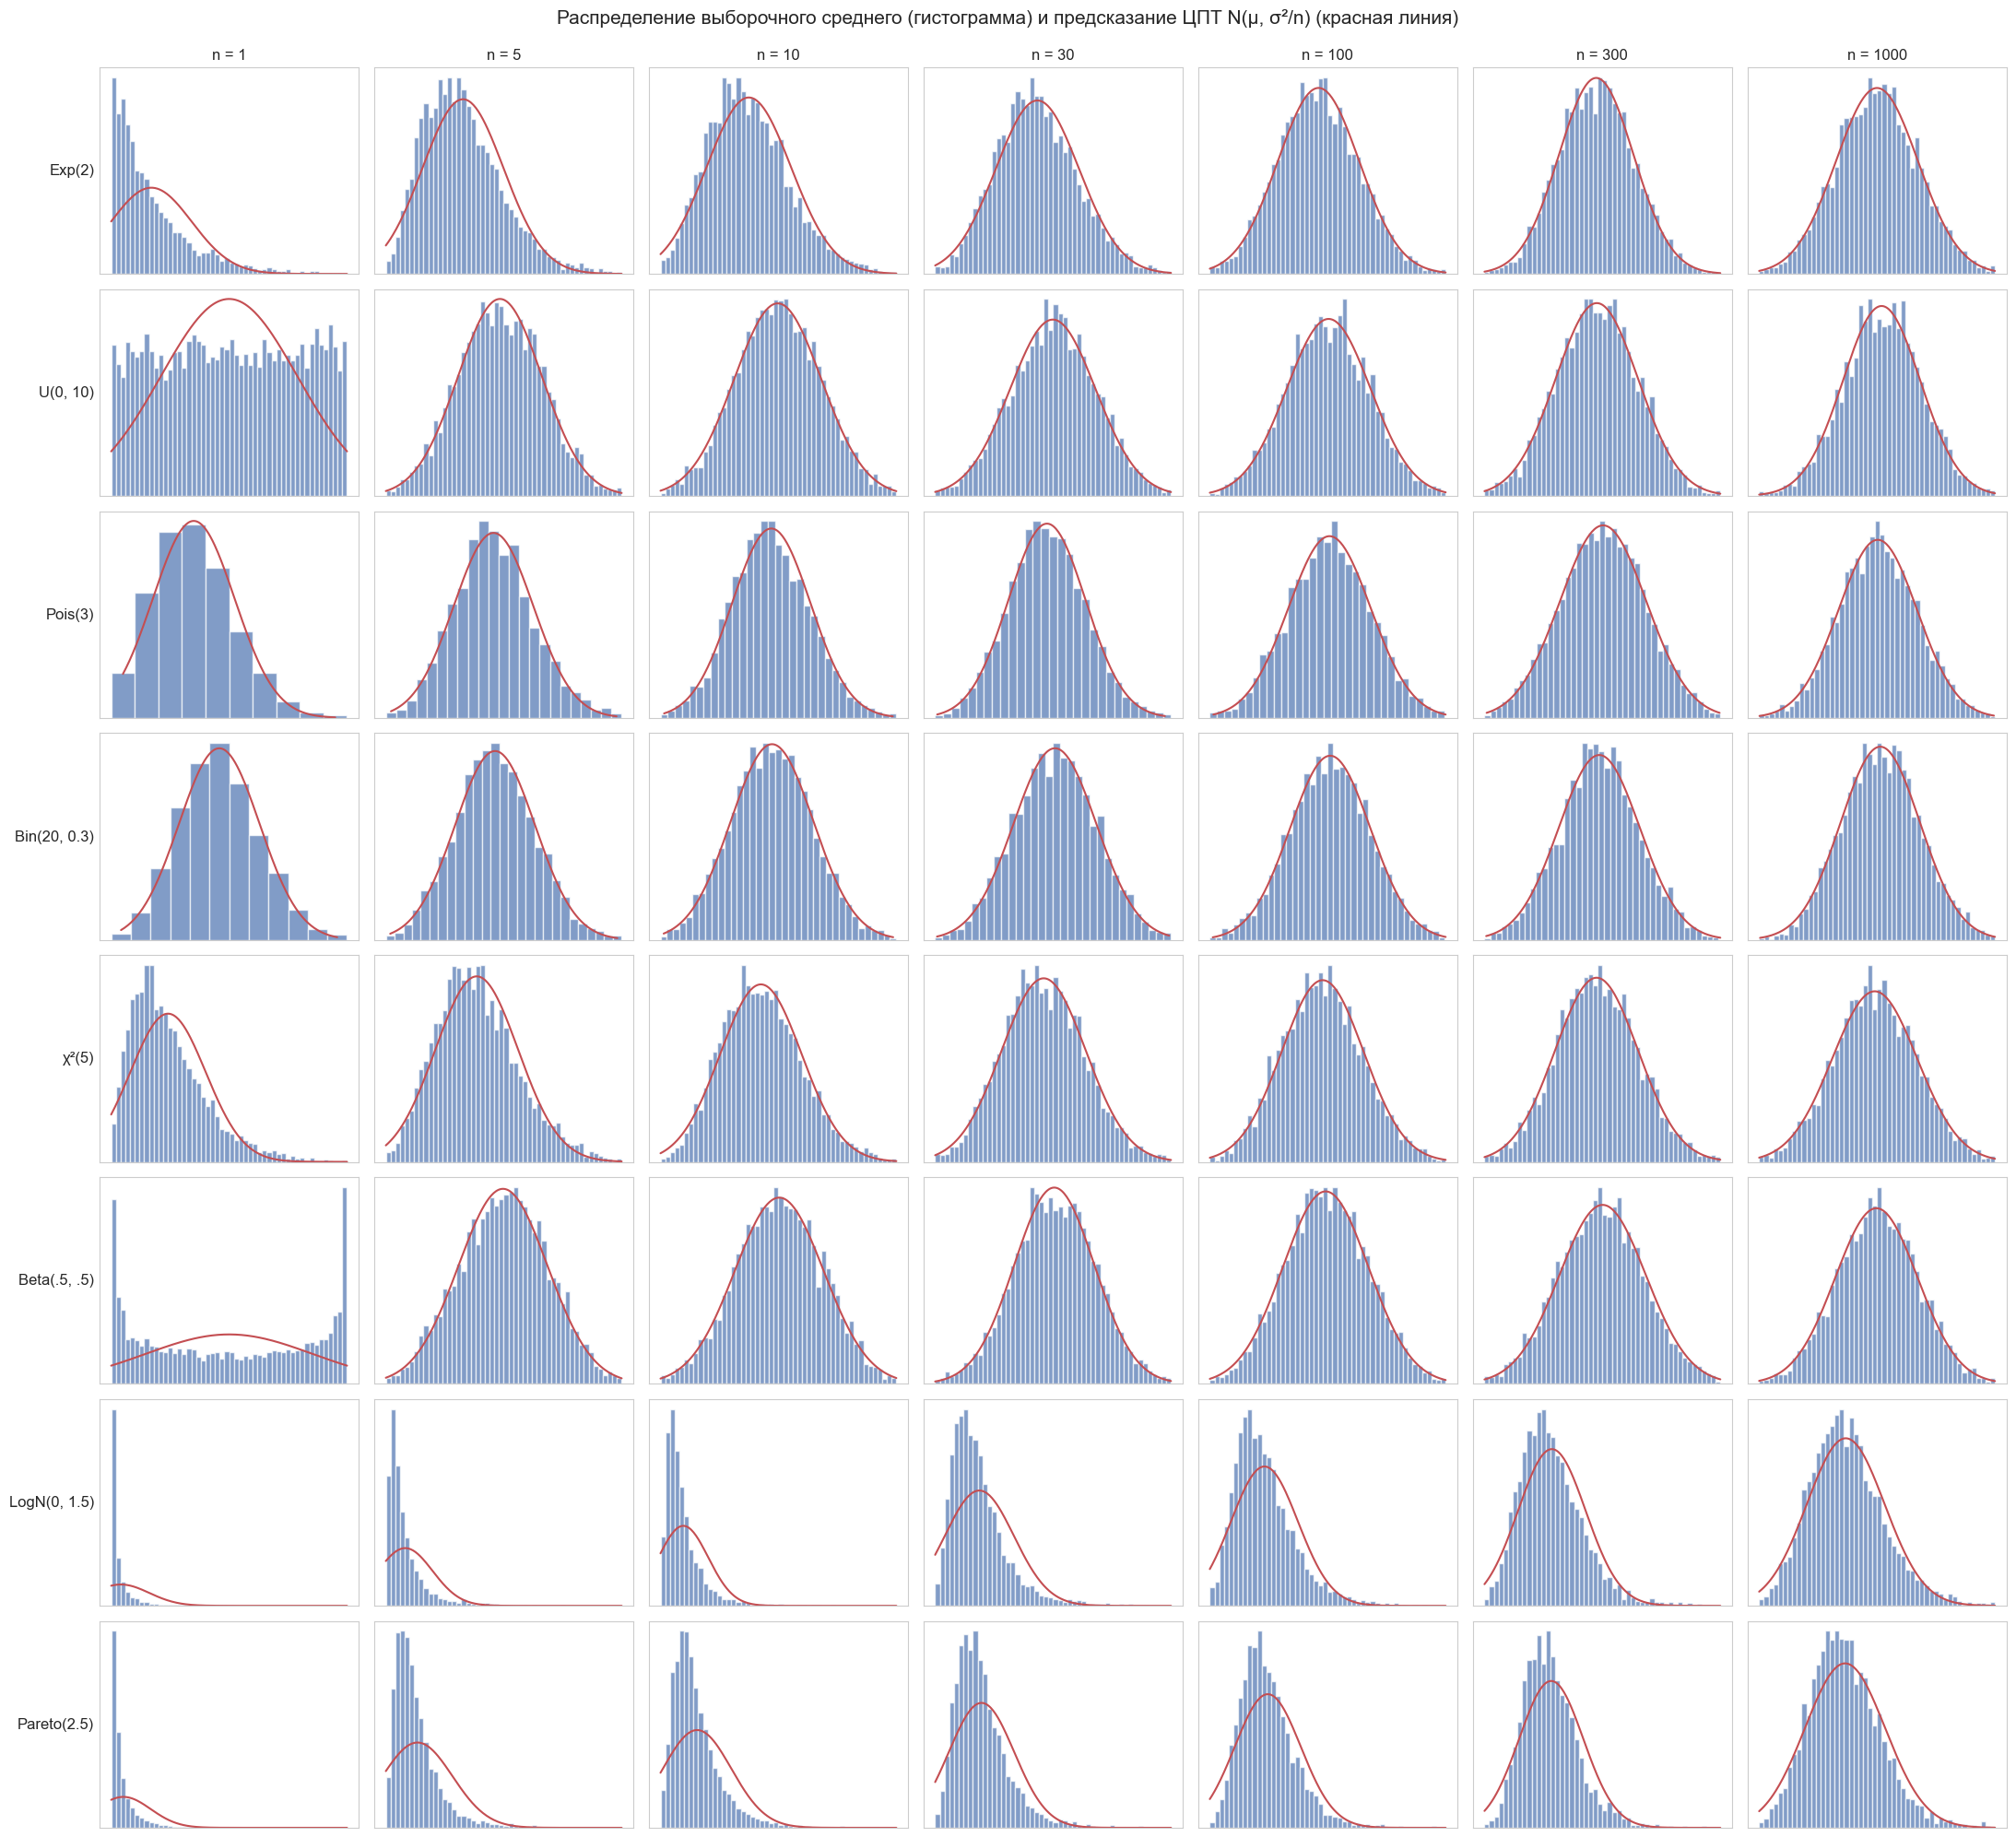

In [5]:
# (название, генератор выборок формы (R, n), теоретическое среднее, теоретическое стандартное отклонение)
LN_S = 1.5
PARETO_A = 2.5
DISTRIBUTIONS = [
    ("Exp(2)",        lambda s: rng.exponential(2.0, s),     2.0, 2.0),
    ("U(0, 10)",      lambda s: rng.uniform(0, 10, s),       5.0, 10 / math.sqrt(12)),
    ("Pois(3)",       lambda s: rng.poisson(3, s),           3.0, math.sqrt(3)),
    ("Bin(20, 0.3)",  lambda s: rng.binomial(20, 0.3, s),    6.0, math.sqrt(20 * 0.3 * 0.7)),
    ("χ²(5)",         lambda s: rng.chisquare(5, s),         5.0, math.sqrt(10)),
    ("Beta(.5, .5)",  lambda s: rng.beta(0.5, 0.5, s),       0.5, math.sqrt(0.25 / 2)),
    ("LogN(0, 1.5)",  lambda s: rng.lognormal(0, LN_S, s),   math.exp(LN_S**2 / 2),
                      math.sqrt((math.exp(LN_S**2) - 1) * math.exp(LN_S**2))),
    ("Pareto(2.5)",   lambda s: rng.pareto(PARETO_A, s) + 1, PARETO_A / (PARETO_A - 1),
                      math.sqrt(PARETO_A / ((PARETO_A - 1)**2 * (PARETO_A - 2)))),
]
SAMPLE_SIZES = [1, 5, 10, 30, 100, 300, 1000]
NUM_SAMPLES = 5000


def plot_clt_grid():
    fig, axes = plt.subplots(len(DISTRIBUTIONS), len(SAMPLE_SIZES), figsize=(22, 20))
    for row, (name, gen, mu, sigma) in enumerate(DISTRIBUTIONS):
        for col, n in enumerate(SAMPLE_SIZES):
            ax = axes[row, col]
            means = gen((NUM_SAMPLES, n)).mean(axis=1)
            lo, hi = np.quantile(means, [0.002, 0.998])   # обрезаем экстремальный хвост для читаемости
            bins = np.linspace(lo, hi, 51)
            if name.startswith(("Pois", "Bin")):          # дискретные: шаг среднего = 1/n, бины по сетке значений
                edges = (np.arange(math.floor(lo * n), math.ceil(hi * n) + 2) - 0.5) / n
                bins = edges[::max(1, math.ceil(len(edges) / 50))]   # каждый бин — целое число шагов решётки
            ax.hist(means, bins=bins, density=True, color="#4C72B0", alpha=0.7)
            grid = np.linspace(lo, hi, 200)
            ax.plot(grid, stats.norm.pdf(grid, mu, sigma / math.sqrt(n)), color="#C44E52", lw=1.5)
            ax.set_xticks([]); ax.set_yticks([])
            if row == 0:
                ax.set_title(f"n = {n}", fontsize=12)
            if col == 0:
                ax.set_ylabel(name, fontsize=12, rotation=0, ha="right", va="center")
    fig.suptitle("Распределение выборочного среднего (гистограмма) и предсказание ЦПТ N(μ, σ²/n) (красная линия)",
                 fontsize=15, y=0.995)
    plt.tight_layout()
    plt.show()


plot_clt_grid()

Для «удобных» распределений приближение становится хорошим уже при $n \approx 30$. Для логнормального и Парето — заметно позже: даже при $n = 100$ распределение среднего скошено вправо. **Скорость сходимости в ЦПТ зависит от хвостов**, а правило «$n \ge 30$ — и всё нормально» на реальной выручке не работает.

### Задание 1. ЦПТ на реальных данных

Реализуйте функцию `sample_means(values, n, R)`: она `R` раз выбирает `n` значений из массива `values` **с возвращением** и возвращает массив из `R` выборочных средних. Генератор случайных чисел — глобальный `rng`.

Затем ячейка проверки построит QQ-графики выборочных средних для выручки клиента и для конверсии в повторный заказ. Ответьте на вопросы:

1. С какого $n$ нормальное приближение выглядит приемлемым для конверсии? А для выручки?
2. Почему для этих двух метрик ответ так сильно отличается?

In [6]:
def sample_means(values: np.ndarray, n: int, R: int = 5000) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [7]:
# @title Решение (нажмите, чтобы раскрыть)
def sample_means(values: np.ndarray, n: int, R: int = 5000) -> np.ndarray:
    idx = rng.integers(0, len(values), size=(R, n))
    return values[idx].mean(axis=1)

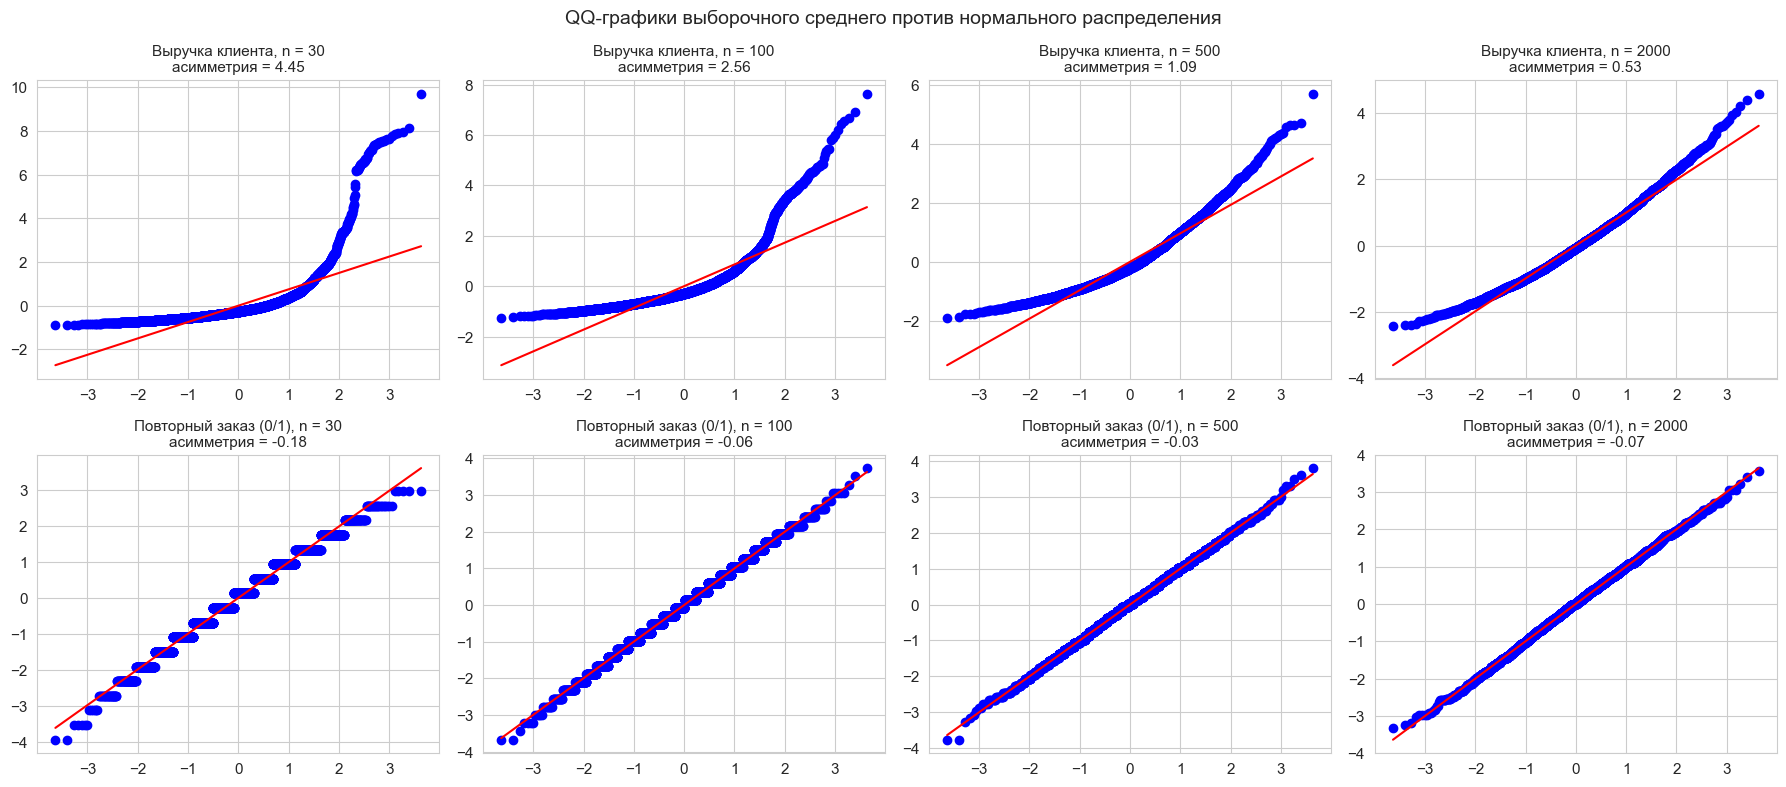

In [8]:
# Проверка
assert sample_means(np.array([1.0, 1.0]), n=5, R=10).shape == (10,)

ns = [30, 100, 500, 2000]
fig, axes = plt.subplots(2, len(ns), figsize=(18, 8))
for row, (name, values) in enumerate([("Выручка клиента", REV), ("Повторный заказ (0/1)", REPEAT)]):
    for col, n in enumerate(ns):
        m = sample_means(values, n)
        stats.probplot((m - m.mean()) / m.std(), dist="norm", plot=axes[row, col])
        axes[row, col].set_title(f"{name}, n = {n}\nасимметрия = {stats.skew(m):.2f}", fontsize=11)
        axes[row, col].set_xlabel(""); axes[row, col].set_ylabel("")
plt.suptitle("QQ-графики выборочного среднего против нормального распределения", fontsize=14)
plt.tight_layout()
plt.show()

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. Для конверсии точки лежат на прямой уже при $n \approx 100$, асимметрия близка к нулю. Для выручки даже при $n = 2000$ правый хвост загибается вверх, асимметрия остаётся заметной.
2. Конверсия — ограниченная величина (0 или 1), у неё «лёгкие» хвосты. Выручка клиента имеет очень тяжёлый хвост: несколько оптовых клиентов приносят сотни тысяч при медиане около тысячи. Скорость сходимости в ЦПТ (неравенство Берри–Эссеена) определяется отношением третьего абсолютного момента к $\sigma^3$, а на тяжёлых хвостах оно огромно. Практический вывод: доверительные интервалы для выручки на «небольших» выборках будут неточными — мы увидим это ниже на покрытии.
</details>

## 2. Асимптотика и дельта-метод

Пусть у нас есть оценка $\hat{\theta}_n$ параметра $\theta$, и мы знаем её асимптотику:

$$
\sqrt{n}(\hat{\theta}_n - \theta) \xrightarrow{d} \mathcal{N}(0, \Sigma).
$$

Часто нас интересует **не сама $\theta$**, а некоторая **функция** $g(\theta)$:

* $g(\theta_1,\theta_2) = \theta_1/\theta_2$ — отношение двух средних (ratio-метрика, например средний чек);
* $g(\mu_A,\mu_B) = \mu_B/\mu_A - 1$ — uplift;
* $g(\theta) = e^\theta$ — например, odds ratio из коэффициента логистической регрессии.

Хочется получить **асимптотическое распределение** $g(\hat{\theta}_n)$, чтобы посчитать её дисперсию и построить доверительный интервал. Стандартный путь — приблизить $g(\hat{\theta}_n)$ **линейной функцией** от $(\hat{\theta}_n - \theta)$ через разложение Тейлора.

**Одномерный дельта-метод.** Пусть $\sqrt{n}(\hat{\theta}_n - \theta) \xrightarrow{d} \mathcal{N}(0, \sigma^2)$, а $g$ дифференцируема в точке $\theta$. Разложение Тейлора первого порядка:

$$
g(\hat{\theta}_n) = g(\theta) + g'(\theta)(\hat{\theta}_n - \theta) + R_n,
$$

где остаток $R_n$ по порядку квадратичен по $(\hat{\theta}_n - \theta)$. Раз $\hat{\theta}_n - \theta = O_p(n^{-1/2})$, то $R_n = O_p(1/n)$ и $\sqrt n R_n \to_p 0$. Умножая на $\sqrt n$ и применяя [теорему Слуцкого](https://ru.wikipedia.org/wiki/Теорема_Слуцкого), получаем

$$
\sqrt{n}\bigl(g(\hat{\theta}_n) - g(\theta)\bigr) \xrightarrow{d} \mathcal{N}\bigl(0,\,[g'(\theta)]^2\sigma^2\bigr),
\qquad
g(\hat{\theta}_n) \approx \mathcal{N}\left(g(\theta),\ \frac{[g'(\theta)]^2\sigma^2}{n}\right).
$$

<details>
<summary>Что значит $O_p(1)$</summary>

Последовательность $X_n$ **ограничена по вероятности**, $X_n = O_p(1)$, если для любого $\epsilon > 0$ найдутся конечные $M_\epsilon$ и $N_\epsilon$, такие что $P(|X_n| > M_\epsilon) < \epsilon$ при всех $n > N_\epsilon$. Условие $\sqrt{n}(\hat{\theta}_n - \theta) = O_p(1)$ говорит о **скорости сходимости**: ошибка оценки убывает как $n^{-1/2}$.
</details>

**Многомерный дельта-метод.** Пусть $\theta\in\mathbb{R}^k$, $\sqrt{n}(\hat{\theta}_n - \theta) \xrightarrow{d} \mathcal{N}(0,\Sigma)$, а $g:\mathbb{R}^k\to\mathbb{R}$ дифференцируема в окрестности $\theta$ с градиентом $\nabla g(\theta)$. Тем же рассуждением

$$
g(\hat{\theta}_n) \approx g(\theta) + \nabla g(\theta)^\top(\hat{\theta}_n - \theta)
\quad\Longrightarrow\quad
g(\hat{\theta}_n) \approx \mathcal{N}\left(g(\theta),\ \frac{1}{n}\,\nabla g(\theta)^\top \Sigma\, \nabla g(\theta)\right).
$$

Смысл простой: около истинной точки гладкая функция ведёт себя почти как линейная, а линейная комбинация нормального вектора снова нормальна.

**Когда дельта-метод работает плохо:**

* функция сильно нелинейна в масштабе разброса оценки (градиент мал, вторые производные велики);
* знаменатель близок к нулю (например, базовая конверсия или средний знаменатель ratio-метрики) — дисперсия «взлетает»;
* выборка мала или хвосты тяжёлые, и сама ЦПТ для $\hat\theta_n$ ещё не «включилась».

### Задание 2. Дисперсия uplift

Пусть в группах A и B независимые выборки размеров $n_A$, $n_B$ с дисперсиями $\sigma_A^2$, $\sigma_B^2$. Выведите с помощью дельта-метода приближённую дисперсию оценки uplift

$$
\hat u = \frac{\hat\mu_B}{\hat\mu_A} - 1.
$$

Подсказка: $\Sigma$ для вектора $(\hat\mu_A, \hat\mu_B)$ диагональна, а вычитание константы не меняет дисперсию.

<details>
<summary><b>Решение</b> (нажмите, чтобы раскрыть)</summary>

Возьмём $\tilde g(\mu_A, \mu_B) = \mu_B/\mu_A$. Градиент:

$$
\nabla \tilde g = \begin{pmatrix} -\mu_B/\mu_A^2 \\[2pt] 1/\mu_A \end{pmatrix},
\qquad
\Sigma_\theta = \begin{pmatrix} \sigma_A^2/n_A & 0 \\ 0 & \sigma_B^2/n_B \end{pmatrix}.
$$

Из-за диагональности $\Sigma_\theta$:

$$
\mathrm{Var}(\hat u) \approx \nabla \tilde g^\top \Sigma_\theta \nabla \tilde g
= \frac{\mu_B^2}{\mu_A^4}\,\frac{\sigma_A^2}{n_A} + \frac{1}{\mu_A^2}\,\frac{\sigma_B^2}{n_B}.
$$

На практике подставляем выборочные средние и дисперсии (plug-in).
</details>

## 3. Типы метрик и общий рецепт ДИ

Перед тем как строить доверительные интервалы, важно зафиксировать:

1. **единицу анализа** — обычно пользователь; именно пользователи рандомизируются по группам;
2. **уровень агрегации** — событие → пользователь → группа;
3. **тип метрики** — value / ratio / перцентиль;
4. **тип эффекта** — absolute $e = \theta_t - \theta_c$ или uplift $u = \theta_t/\theta_c - 1$.

| Тип | Определение | Примеры | В нашем датасете |
|---|---|---|---|
| **Value** | среднее поюзерной величины: $\hat\mu = \frac1n\sum X_i$ | выручка на пользователя, конверсия (среднее 0/1) | `revenue`, `repeat` |
| **Ratio** | отношение средних: $\hat R = \bar X / \bar Y$ | CTR = клики / показы, средний чек = выручка / заказы | `revenue / n_orders` |
| **Перцентиль** | квантиль $x_p = F^{-1}(p)$ | p95 времени доставки, p99 latency | p95 суммы заказа |

Почти все формулы ниже устроены одинаково:

1. Записываем оценку метрики как функцию $g$ от «простых» средних, например $g(\mu_X,\mu_Y)=\mu_X/\mu_Y$.
2. По ЦПТ вектор средних асимптотически нормален: $\sqrt{n}(\hat{\theta}-\theta)\Rightarrow \mathcal{N}(0,\Sigma)$.
3. Линеаризуем $g$ (дельта-метод): $\mathrm{Var}(g(\hat{\theta}))\approx \frac{1}{n}\nabla g^\top \Sigma \nabla g$, $\ \mathrm{SE}=\sqrt{\mathrm{Var}}$.
4. Подставляем оценки вместо неизвестных параметров и строим ДИ: $\ \hat g \pm z_{1-\alpha/2}\,\widehat{\mathrm{SE}}$.

Всё отличие между метриками — в том, **что считать за $\theta$, какая функция $g$ и как оценить $\Sigma$**.

## 4. Value-метрики

В группе A наблюдаем поюзерные значения $Z_1^A,\dots,Z_{n_A}^A$, в группе B — $Z_1^B,\dots,Z_{n_B}^B$; группы независимы.

**Absolute effect.** $\Delta_{\text{abs}} = \mu_B - \mu_A$ — линейная комбинация двух независимых асимптотически нормальных оценок, поэтому дисперсии просто складываются, и дельта-метод не нужен:

$$
\widehat{\mathrm{SE}}(\hat\Delta_{\text{abs}}) = \sqrt{\frac{\hat{\sigma}_A^2}{n_A} + \frac{\hat{\sigma}_B^2}{n_B}},
\qquad
\hat\Delta_{\text{abs}} \pm z_{1-\alpha/2}\, \widehat{\mathrm{SE}}.
$$

**Uplift.** $\Delta_{\text{rel}} = \mu_B/\mu_A - 1$ — нелинейная функция, дисперсию даёт результат задания 2:

$$
\widehat{\mathrm{Var}}(\hat\Delta_{\text{rel}}) = \frac{\hat\mu_B^2}{\hat\mu_A^4}\,\frac{\hat\sigma_A^2}{n_A} + \frac{1}{\hat\mu_A^2}\,\frac{\hat\sigma_B^2}{n_B}.
$$

### Задание 3. ДИ для value-метрик

Реализуйте две функции. Обе принимают массивы поюзерных значений контроля `x_c` и теста `x_t` и возвращают тройку `(оценка, (нижняя граница, верхняя граница), SE)`. Выборочные дисперсии — с `ddof=1`.

* `ci_mean_abs` — ДИ для разности средних;
* `ci_mean_uplift_delta` — ДИ для uplift через дельта-метод.

In [9]:
def z_crit(alpha: float = 0.05) -> float:
    """Квантиль стандартного нормального распределения z_{1-alpha/2}."""
    return NormalDist().inv_cdf(1 - alpha / 2)


def ci_mean_abs(x_c, x_t, alpha: float = 0.05):
    # ВАШ КОД
    raise NotImplementedError


def ci_mean_uplift_delta(x_c, x_t, alpha: float = 0.05):
    # ВАШ КОД
    raise NotImplementedError

In [10]:
# @title Решение (нажмите, чтобы раскрыть)
def ci_mean_abs(x_c, x_t, alpha: float = 0.05):
    x_c = np.asarray(x_c, float); x_t = np.asarray(x_t, float)
    delta = x_t.mean() - x_c.mean()
    se = math.sqrt(x_c.var(ddof=1) / len(x_c) + x_t.var(ddof=1) / len(x_t))
    z = z_crit(alpha)
    return delta, (delta - z * se, delta + z * se), se


def ci_mean_uplift_delta(x_c, x_t, alpha: float = 0.05):
    x_c = np.asarray(x_c, float); x_t = np.asarray(x_t, float)
    mu_c, mu_t = x_c.mean(), x_t.mean()
    u = mu_t / mu_c - 1
    # dg/dmu_t = 1/mu_c,  dg/dmu_c = -mu_t/mu_c^2
    var = x_t.var(ddof=1) / len(x_t) / mu_c**2 + x_c.var(ddof=1) / len(x_c) * mu_t**2 / mu_c**4
    se = math.sqrt(var)
    z = z_crit(alpha)
    return u, (u - z * se, u + z * se), se

**Проверка 1: один эксперимент.** Разобьём всех клиентов на две группы хешированием `user_id` (как это делает реальная A/B-платформа) — это A/A-тест. Затем «включим» эффект: умножим выручку теста на 1.05.

In [11]:
def hash_group(user_id, salt="practice-1"):
    h = hashlib.md5(f"{salt}:{user_id}".encode()).hexdigest()
    return "t" if int(h, 16) % 2 else "c"


users["group"] = users["user_id"].map(hash_group)
rev_c = users.loc[users.group == "c", "revenue"].to_numpy()
rev_t = users.loc[users.group == "t", "revenue"].to_numpy()
print(f"группы: c = {len(rev_c)}, t = {len(rev_t)}")

for title, x_t in [("A/A", rev_t), ("A/B, истинный uplift +5%", rev_t * 1.05)]:
    est, (lo, hi), se = ci_mean_abs(rev_c, x_t)
    print(f"{title:>26} | abs:    {est:8.1f}  ДИ [{lo:8.1f}, {hi:8.1f}]")
    est, (lo, hi), se = ci_mean_uplift_delta(rev_c, x_t)
    print(f"{'':>26} | uplift: {est:8.2%}  ДИ [{lo:8.2%}, {hi:8.2%}]")

группы: c = 2993, t = 2885
                       A/A | abs:       528.0  ДИ [  -235.1,   1291.1]
                           | uplift:   19.14%  ДИ [  -9.40%,   47.67%]
  A/B, истинный uplift +5% | abs:       692.4  ДИ [  -103.1,   1487.9]
                           | uplift:   25.09%  ДИ [  -4.87%,   55.05%]


Обратите внимание: даже на всех ~5.9 тыс. клиентах ДИ для uplift выручки получается шириной в десятки процентов. Эффект +5% на такой метрике и таком трафике не обнаружить — это прямое следствие тяжёлого хвоста выручки.

**Проверка 2: покрытие.** Повторим эксперимент 1000 раз на выборках разного размера и посчитаем, как часто ДИ накрывает истину. Для честного 95% ДИ ожидаем ≈ 0.95 (с точностью ±0.014 при 1000 повторениях).

In [12]:
def exp_value_abs(values, n):
    def run():
        c, t = sample_users(n), sample_users(n)
        _, (lo, hi), _ = ci_mean_abs(values[c], values[t])
        return lo, hi, 0.0                      # A/A: истинный эффект 0
    return run


def exp_value_uplift(values, n, lift=0.05):
    def run():
        c, t = sample_users(n), sample_users(n)
        _, (lo, hi), _ = ci_mean_uplift_delta(values[c], values[t] * (1 + lift))
        return lo, hi, lift                     # A/B: истинный uplift = lift
    return run


rows = []
for n in [200, 1000, 3000]:
    rows.append({"n в группе": n,
                 "конверсия, abs": coverage(exp_value_abs(REPEAT, n)),
                 "выручка, abs": coverage(exp_value_abs(REV, n)),
                 "выручка, uplift": coverage(exp_value_uplift(REV, n))})
pd.DataFrame(rows).set_index("n в группе")

,"конверсия, abs","выручка, abs","выручка, uplift"
n в группе,,,
200,0.948,0.976,0.856
1000,0.943,0.958,0.943
3000,0.964,0.969,0.942


Для конверсии покрытие честное при любом $n$. Для uplift выручки — заниженное на малых выборках (около 0.86 при $n = 200$) и приближается к 0.95 только с ростом $n$. ДИ для абсолютной разности выручки, наоборот, слегка консервативен (покрытие выше 0.95): когда в выборку попадает крупный клиент, оценка дисперсии резко раздувается.

**Вопрос.** Почему именно uplift выручки «недокрывает», и что с этим можно сделать?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Uplift — отношение двух средних с тяжёлым хвостом. В выборку то попадают, то не попадают крупные оптовые клиенты: в первом случае и среднее, и его выборочная дисперсия резко растут, т.е. оценка и её SE сильно коррелируют, а распределение $\hat u$ скошено. Линейное приближение дельта-метода и нормальная аппроксимация ЦПТ на таких выборках ещё неточны (см. задание 1).

Что делать: увеличивать выборку; обрабатывать выбросы и снижать дисперсию (занятие 1.04); проверять результат бутстрапом (занятие 1.01); строить ДИ для $\log(\mu_B/\mu_A)$ и экспоненцировать границы (см. дополнительные задания).
</details>

**Бутстрап как sanity-check.** Сравним дельта-метод с перцентильным бутстрапом из занятия 1.01 на одном A/B-эксперименте:

In [13]:
def bootstrap_ci_2sample(x_c, x_t, stat_fn, B=2000, alpha=0.05, seed=0):
    """Перцентильный бутстрап-ДИ для двух независимых выборок пользователей."""
    r = np.random.default_rng(seed)
    x_c = np.asarray(x_c, float); x_t = np.asarray(x_t, float)
    boot = np.array([stat_fn(x_c[r.integers(0, len(x_c), len(x_c))],
                             x_t[r.integers(0, len(x_t), len(x_t))]) for _ in range(B)])
    return stat_fn(x_c, x_t), tuple(np.quantile(boot, [alpha / 2, 1 - alpha / 2]))


c, t = sample_users(1000), sample_users(1000)
x_c, x_t = REV[c], REV[t] * 1.05
est, ci_delta, _ = ci_mean_uplift_delta(x_c, x_t)
_, ci_boot = bootstrap_ci_2sample(x_c, x_t, lambda a, b: b.mean() / a.mean() - 1)
print(f"uplift = {est:.2%}")
print(f"дельта-метод: [{ci_delta[0]:.2%}, {ci_delta[1]:.2%}]")
print(f"бутстрап:     [{ci_boot[0]:.2%}, {ci_boot[1]:.2%}]")

uplift = 12.16%
дельта-метод: [-31.10%, 55.42%]
бутстрап:     [-23.31%, 65.73%]


Бутстрап-интервал обычно несимметричен — он «видит» скошенность распределения $\hat u$, которую дельта-метод с симметричным $\pm z\cdot SE$ игнорирует.

## 5. Ratio-метрики

Для каждого пользователя $i=1,\dots,n$ наблюдаем пару $(X_i, Y_i)$: $X_i$ — числитель (выручка, клики), $Y_i$ — знаменатель (заказы, показы), $\mathbb E Y_i > 0$. Нас интересует параметр **на уровне популяции**

$$
r = \frac{\mu_X}{\mu_Y}, \qquad \hat r = \frac{\bar X}{\bar Y} = \frac{\sum_i X_i}{\sum_i Y_i}.
$$

*Это **отношение средних**, а не среднее индивидуальных отношений $X_i/Y_i$ — другая оценка со своим поведением.*

По ЦПТ вектор $(\bar X, \bar Y)$ асимптотически нормален с ковариацией $\Sigma/n$, где $\Sigma = \begin{pmatrix} \sigma_X^2 & \sigma_{XY} \\ \sigma_{XY} & \sigma_Y^2 \end{pmatrix}$. Для $g(\mu_X,\mu_Y) = \mu_X/\mu_Y$ градиент $\nabla g = \left(1/\mu_Y,\ -\mu_X/\mu_Y^2\right)^\top$, и раскрытие квадратичной формы $\nabla g^\top\Sigma\nabla g$ даёт:

$$
\mathrm{Var}(\hat{r}) \approx \frac{1}{n}\left[ \frac{\sigma_X^2}{\mu_Y^2} + \frac{\mu_X^2}{\mu_Y^4}\sigma_Y^2 - 2\frac{\mu_X}{\mu_Y^3}\sigma_{XY} \right].
$$

Слагаемые — вклад вариации числителя, вклад вариации знаменателя и поправка на их корреляцию. На практике подставляем выборочные средние, дисперсии и ковариацию (с $\frac{1}{n-1}$).

**Эффекты для ratio-метрики** в двух независимых группах:

* absolute: $\Delta = r_B - r_A$, $\ \widehat{\mathrm{Var}}(\hat\Delta) = \widehat{\mathrm{Var}}(\hat r_A) + \widehat{\mathrm{Var}}(\hat r_B)$;
* uplift: $u = r_B/r_A - 1$ — ещё раз дельта-метод, теперь для функции $h(r_A, r_B) = r_B/r_A$:

$$
\widehat{\mathrm{Var}}(\hat u) = \frac{\hat r_B^2}{\hat r_A^4}\,\widehat{\mathrm{Var}}(\hat r_A) + \frac{1}{\hat r_A^2}\,\widehat{\mathrm{Var}}(\hat r_B).
$$

### Задание 4. ДИ для ratio-метрик

Реализуйте:

* `var_ratio_delta(x, y)` — дельта-оценку $\widehat{\mathrm{Var}}(\hat r)$ по поюзерным массивам числителя и знаменателя;
* `ci_ratio_abs_delta(x_c, y_c, x_t, y_t)` и `ci_ratio_uplift_delta(x_c, y_c, x_t, y_t)` — ДИ для абсолютного эффекта и uplift; формат ответа такой же, как в задании 3.

Наша ratio-метрика — **средний чек**: $X_i$ = выручка клиента, $Y_i$ = число его заказов.

In [14]:
def var_ratio_delta(x, y) -> float:
    # ВАШ КОД
    raise NotImplementedError


def ci_ratio_abs_delta(x_c, y_c, x_t, y_t, alpha: float = 0.05):
    # ВАШ КОД
    raise NotImplementedError


def ci_ratio_uplift_delta(x_c, y_c, x_t, y_t, alpha: float = 0.05):
    # ВАШ КОД
    raise NotImplementedError

In [15]:
# @title Решение (нажмите, чтобы раскрыть)
def var_ratio_delta(x, y) -> float:
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    cxy = np.cov(x, y, ddof=1)[0, 1]
    return float((vx / my**2 + mx**2 * vy / my**4 - 2 * mx * cxy / my**3) / n)


def ci_ratio_abs_delta(x_c, y_c, x_t, y_t, alpha: float = 0.05):
    r_c = np.sum(x_c) / np.sum(y_c)
    r_t = np.sum(x_t) / np.sum(y_t)
    delta = r_t - r_c
    se = math.sqrt(var_ratio_delta(x_c, y_c) + var_ratio_delta(x_t, y_t))
    z = z_crit(alpha)
    return delta, (delta - z * se, delta + z * se), se


def ci_ratio_uplift_delta(x_c, y_c, x_t, y_t, alpha: float = 0.05):
    r_c = np.sum(x_c) / np.sum(y_c)
    r_t = np.sum(x_t) / np.sum(y_t)
    u = r_t / r_c - 1
    # dh/dr_t = 1/r_c,  dh/dr_c = -r_t/r_c^2
    var = var_ratio_delta(x_t, y_t) / r_c**2 + r_t**2 / r_c**4 * var_ratio_delta(x_c, y_c)
    se = math.sqrt(var)
    z = z_crit(alpha)
    return u, (u - z * se, u + z * se), se

**Проверка 1: формула дисперсии.** Сравним дельта-оценку дисперсии среднего чека с эмпирической дисперсией $\hat r$ по 3000 выборкам из 1000 клиентов.

In [16]:
r_hats, delta_vars = [], []
for _ in range(3000):
    idx = sample_users(1000)
    r_hats.append(REV[idx].sum() / N_ORD[idx].sum())
    delta_vars.append(var_ratio_delta(REV[idx], N_ORD[idx]))

emp_var, mean_delta_var = np.var(r_hats, ddof=1), np.mean(delta_vars)
print(f"Эмпирическая дисперсия Var(r_hat): {emp_var:.2f}")
print(f"Средняя дельта-оценка Var(r_hat): {mean_delta_var:.2f}")
print(f"Относительная ошибка: {mean_delta_var / emp_var - 1:+.1%}")

Эмпирическая дисперсия Var(r_hat): 3478.59
Средняя дельта-оценка Var(r_hat): 3325.62
Относительная ошибка: -4.4%


**Проверка 2: покрытие и цена наивного подхода.** Частая ошибка — считать средний чек как обычное среднее **по заказам**, будто заказы независимы, и строить ДИ по формуле для value-метрики. Но рандомизируем мы клиентов, а заказы одного клиента похожи друг на друга. Сравним покрытие:

In [17]:
def exp_ratio_abs(n):
    def run():
        c, t = sample_users(n), sample_users(n)
        _, (lo, hi), _ = ci_ratio_abs_delta(REV[c], N_ORD[c], REV[t], N_ORD[t])
        return lo, hi, 0.0
    return run


def exp_ratio_uplift(n, lift=0.05):
    def run():
        c, t = sample_users(n), sample_users(n)
        _, (lo, hi), _ = ci_ratio_uplift_delta(REV[c], N_ORD[c], REV[t] * (1 + lift), N_ORD[t])
        return lo, hi, lift
    return run


def exp_ratio_naive(n):
    def run():
        c, t = sample_users(n), sample_users(n)
        _, (lo, hi), _ = ci_mean_abs(orders_of(c)[0], orders_of(t)[0])   # заказы как независимые наблюдения
        return lo, hi, 0.0
    return run


rows = []
for n in [200, 1000, 3000]:
    rows.append({"n в группе": n,
                 "наивный (по заказам)": coverage(exp_ratio_naive(n)),
                 "дельта-метод, abs": coverage(exp_ratio_abs(n)),
                 "дельта-метод, uplift": coverage(exp_ratio_uplift(n))})
pd.DataFrame(rows).set_index("n в группе")

,наивный (по заказам),"дельта-метод, abs","дельта-метод, uplift"
n в группе,,,
200,0.398,0.943,0.867
1000,0.406,0.964,0.914
3000,0.425,0.959,0.931


Наивный «95%» ДИ накрывает истину лишь примерно в 40% случаев: в A/A-тестах он будет «находить» эффект примерно в 60% запусков вместо заявленных 5%. Дельта-метод на уровне клиентов даёт честное покрытие для абсолютного эффекта; для uplift, как и в случае выручки, покрытие занижено на малых выборках из-за тяжёлых хвостов и выравнивается с ростом $n$.

<details>
<summary><b>Почему наивный подход так ошибается</b> (нажмите, чтобы раскрыть)</summary>

Заказы внутри клиента коррелированы: оптовик стабильно делает крупные заказы, розничный покупатель — мелкие. Формула $s^2/K$ по $K$ заказам предполагает, что все заказы — независимая информация. На деле эффективный объём выборки ближе к числу клиентов, чем к числу заказов, а дисперсия занижается примерно в $1 + (\bar m - 1)\rho$ раз, где $\bar m$ — среднее число заказов на клиента, $\rho$ — внутриклиентская корреляция. Правило: **дисперсию считаем на уровне единицы рандомизации**.
</details>

**Линеаризация** (подробно — в занятии 1.04) — другой способ корректно проверить гипотезу о ratio-метрике: вместо неё сравнивают средние поюзерной величины $L_i = X_i - \hat r_c Y_i$, где $\hat r_c$ — значение ratio в контроле. Это обычная value-метрика, к ней применим $z$-тест из раздела 4. При $H_0$ ($r_t = r_c$) такой тест асимптотически эквивалентен дельта-методу. Проверим на A/A-тестах, что оба подхода держат долю ложных прокрасов около 5%:

In [18]:
def exp_linearized_aa(n):
    def run():
        c, t = sample_users(n), sample_users(n)
        r_c = REV[c].sum() / N_ORD[c].sum()
        L_c, L_t = REV[c] - r_c * N_ORD[c], REV[t] - r_c * N_ORD[t]
        _, (lo, hi), _ = ci_mean_abs(L_c, L_t)
        return lo, hi, 0.0
    return run


n = 1000
print(f"Доля ложных прокрасов в A/A, n = {n} в группе:")
print(f"  дельта-метод:  {1 - coverage(exp_ratio_abs(n)):.3f}")
print(f"  линеаризация:  {1 - coverage(exp_linearized_aa(n)):.3f}")

Доля ложных прокрасов в A/A, n = 1000 в группе:
  дельта-метод:  0.046
  линеаризация:  0.046


Обратите внимание: эквивалентность касается **проверки гипотезы**. Если перевести ДИ линеаризованной метрики обратно в единицы ratio (поделив на средний знаменатель), он будет близок к ДИ дельта-метода, но не совпадёт с ним в точности — особенно когда эффект ненулевой.

## 6. Перцентильные метрики

Перцентили стоят особняком: для их ДИ обычно используют **ранги** (порядковые статистики), а не формулу «оценка ± z·SE».

### Независимые данные

Пусть $X_1, \dots, X_n$ независимы, и мы оцениваем квантиль $x_p$: $\ \mathbb{P}(X_i \le x_p) = p$. Индикатор $I\{X_i \le x_p\}$ — бернуллиевская величина, и доля наблюдений ниже квантиля по ЦПТ

$$
\frac1n \sum_{i=1}^n I\{X_i \le x_p\} \approx \mathcal{N}\!\left(p,\ \sigma^2\right), \qquad \sigma = \sqrt{\frac{p(1-p)}{n}}.
$$

Нормальный ДИ для этой доли $[p - z_{1-\alpha/2}\sigma,\ p + z_{1-\alpha/2}\sigma]$, умноженный на $n$, превращается в **интервал рангов**:

$$
L = n \left(p - z_{1-\alpha/2}\, \sigma\right), \qquad
U = n \left(p + z_{1-\alpha/2}\, \sigma\right) + 1,
$$

и ДИ для квантиля — это $\left[X_{(L)},\ X_{(U)}\right]$, где $X_{(1)} \le \dots \le X_{(n)}$ — отсортированная выборка (ранги округляем наружу).

### Данные, кластеризованные по пользователю

Часто метрика считается по событиям (заказы, поездки), а рандомизация — по пользователям. События одного пользователя зависимы, и формула $\sigma = \sqrt{p(1-p)/K}$ по $K$ событиям занижает разброс. Решение — заметить, что доля событий ниже квантиля — это **ratio-метрика**:

1. для пользователя $i$ считаем число событий $N_i$ и число событий ниже оценки квантиля $S_i = \sum_{k \in i} I\{X_k \le \hat x_p\}$;
2. $\hat p = \sum_i S_i / \sum_i N_i$ — отношение средних, его дисперсия $\widehat{\mathrm{Var}}(\hat p)$ — это `var_ratio_delta(S, N)` из раздела 5;
3. подставляем $\hat\sigma_{\text{eff}} = \sqrt{\widehat{\mathrm{Var}}(\hat p)}$ вместо $\sigma$ в формулы для $L$ и $U$, где $n$ заменяется на число событий $K$.

Подход описан в [Deng, Knoblich, Lu (2018)](https://arxiv.org/abs/1803.06336) и [Liu et al. (2019)](https://arxiv.org/abs/1903.08762).

In [19]:
def quantile_order_stat(x, p: float) -> float:
    """Точечная оценка квантиля: порядковая статистика X_(ceil(n p))."""
    xs = np.sort(np.asarray(x, float))
    k = min(max(math.ceil(len(xs) * p), 1), len(xs))
    return float(xs[k - 1])


def _rank_ci(xs_sorted, p, sigma, alpha):
    K = len(xs_sorted)
    z = z_crit(alpha)
    L = min(max(math.floor(K * (p - z * sigma)), 1), K)
    U = min(max(math.ceil(K * (p + z * sigma) + 1), 1), K)
    return float(xs_sorted[L - 1]), float(xs_sorted[U - 1])


def ci_quantile_rank_iid(x, p: float = 0.95, alpha: float = 0.05):
    """Ранговый ДИ для квантиля в предположении независимых наблюдений."""
    xs = np.sort(np.asarray(x, float))
    sigma = math.sqrt(p * (1 - p) / len(xs))
    return quantile_order_stat(xs, p), _rank_ci(xs, p, sigma, alpha)

### Задание 5. Перцентильный ДИ с учётом кластеризации

Реализуйте `ci_quantile_rank_cluster(x, groups, p, alpha)`: `x` — значения событий, `groups` — номер пользователя для каждого события (целые числа от 0). Верните `(оценка квантиля, (L-граница, U-граница))`.

Подсказки: `np.bincount(groups, weights=...)` считает суммы по пользователям; для ранговых границ используйте готовую `_rank_ci`.

In [20]:
def ci_quantile_rank_cluster(x, groups, p: float = 0.95, alpha: float = 0.05):
    # ВАШ КОД
    raise NotImplementedError

In [21]:
# @title Решение (нажмите, чтобы раскрыть)
def ci_quantile_rank_cluster(x, groups, p: float = 0.95, alpha: float = 0.05):
    x = np.asarray(x, float)
    xs = np.sort(x)
    q_hat = quantile_order_stat(xs, p)
    S = np.bincount(groups, weights=(x <= q_hat).astype(float))   # событий ниже квантиля у пользователя
    N = np.bincount(groups).astype(float)                         # всего событий у пользователя
    sigma_eff = math.sqrt(var_ratio_delta(S, N))
    return q_hat, _rank_ci(xs, p, sigma_eff, alpha)

**Проверка: покрытие для p95 суммы заказа.** Истина — 95-й перцентиль по всем заказам генеральной совокупности. В каждом эксперименте выбираем клиентов и берём все их заказы.

In [22]:
TRUE_P95 = quantile_order_stat(ORDER_VALUES, 0.95)
print(f"Истинный p95 суммы заказа: {TRUE_P95:.1f}")


def exp_quantile(n, method):
    def run():
        x, g = orders_of(sample_users(n))
        _, (lo, hi) = ci_quantile_rank_iid(x) if method == "iid" else ci_quantile_rank_cluster(x, g)
        return lo, hi, TRUE_P95
    return run


rows = []
for n in [200, 1000, 3000]:
    rows.append({"клиентов в выборке": n,
                 "iid ранговый ДИ": coverage(exp_quantile(n, "iid")),
                 "кластерный ДИ": coverage(exp_quantile(n, "cluster"))})
pd.DataFrame(rows).set_index("клиентов в выборке")

Истинный p95 суммы заказа: 1253.9


,iid ранговый ДИ,кластерный ДИ
клиентов в выборке,,
200,0.400,0.847
1000,0.389,0.889
3000,0.376,0.929


iid-интервал, игнорирующий кластеризацию, накрывает истину лишь примерно в 40% случаев. Кластерная поправка исправляет главную ошибку, но покрытие всё ещё ниже номинального: около 0.85 при 200 клиентах и около 0.93 при 3000. Это асимптотический метод, а для хвостового квантиля (p95) на сильно кластеризованных данных с тяжёлым хвостом сходимость медленная: в хвост попадает немного событий, и сосредоточены они у небольшого числа крупных клиентов. На практике для таких метрик нужны большие выборки или проверка кластерным бутстрапом.

**Эффект по перцентилю.** Для разности квантилей $x_{p,t} - x_{p,c}$ аналитическая формула требует оценки плотности в точке квантиля, поэтому на практике чаще используют **кластерный бутстрап**: ресэмплируем пользователей, а не события. Проверим на A/B, где все заказы теста на 5% дороже:

In [23]:
def bootstrap_ci_quantile_diff_cluster(idx_c, idx_t, p=0.95, lift_t=0.0, B=1000, alpha=0.05, seed=0):
    """Кластерный бутстрап для q_t - q_c: ресэмплируем клиентов внутри каждой группы."""
    r = np.random.default_rng(seed)
    q = lambda idx, k: quantile_order_stat(orders_of(idx)[0] * k, p)
    est = q(idx_t, 1 + lift_t) - q(idx_c, 1.0)
    boot = [q(idx_t[r.integers(0, len(idx_t), len(idx_t))], 1 + lift_t)
            - q(idx_c[r.integers(0, len(idx_c), len(idx_c))], 1.0) for _ in range(B)]
    return est, tuple(np.quantile(boot, [alpha / 2, 1 - alpha / 2]))


idx_c, idx_t = sample_users(2000), sample_users(2000)
est, (lo, hi) = bootstrap_ci_quantile_diff_cluster(idx_c, idx_t, lift_t=0.05)
print(f"истинный эффект: {0.05 * TRUE_P95:.1f}")
print(f"оценка: {est:.1f}, кластерный бутстрап-ДИ: [{lo:.1f}, {hi:.1f}]")

истинный эффект: 62.7
оценка: -180.7, кластерный бутстрап-ДИ: [-742.7, 240.0]


ДИ получается широким: p95 суммы заказа — шумная метрика, и сдвиг на 5% при 2000 клиентах в группе с ней не обнаружить.

## 7. Итоги

| Тип метрики | Эффект | Оценка | Оценка дисперсии / SE | Доверительный интервал |
|-------------|--------|--------|----------------------|------------------------|
| **Value** | **Absolute**<br>$e=\mu_t-\mu_c$ | $\hat e=\bar X_t-\bar X_c$ | $\widehat{\mathrm{Var}}(\hat e)=\dfrac{s_t^2}{n_t}+\dfrac{s_c^2}{n_c}$ | $\hat e \pm z_{1-\alpha/2}\widehat{\mathrm{SE}}$ |
| **Value** | **Uplift**<br>$u=\mu_t/\mu_c-1$ | $\hat u=\bar X_t/\bar X_c-1$ | $\widehat{\mathrm{Var}}(\hat u)=\dfrac{s_t^2}{n_t}\dfrac{1}{\bar X_c^2}+\dfrac{s_c^2}{n_c}\dfrac{\bar X_t^2}{\bar X_c^4}$ | $\hat u \pm z_{1-\alpha/2}\widehat{\mathrm{SE}}$ |
| **Ratio** | **В группе**<br>$r=\mu_X/\mu_Y$ | $\hat r=\dfrac{\sum X_i}{\sum Y_i}$ | $\widehat{\mathrm{Var}}(\hat r)=\dfrac{1}{n}\Bigl[\dfrac{s_X^2}{\bar Y^2}-2\dfrac{\bar X}{\bar Y^3}s_{XY}+\dfrac{\bar X^2}{\bar Y^4}s_Y^2\Bigr]$ | $\hat r \pm z_{1-\alpha/2}\widehat{\mathrm{SE}}$ |
| **Ratio** | **Absolute**<br>$e=r_t-r_c$ | $\hat e=\hat r_t-\hat r_c$ | $\widehat{\mathrm{Var}}(\hat r_t)+\widehat{\mathrm{Var}}(\hat r_c)$ | $\hat e \pm z_{1-\alpha/2}\widehat{\mathrm{SE}}$ |
| **Ratio** | **Uplift**<br>$u=r_t/r_c-1$ | $\hat u=\hat r_t/\hat r_c-1$ | $\dfrac{1}{\hat r_c^2}\widehat{\mathrm{Var}}(\hat r_t)+\dfrac{\hat r_t^2}{\hat r_c^4}\widehat{\mathrm{Var}}(\hat r_c)$ | $\hat u \pm z_{1-\alpha/2}\widehat{\mathrm{SE}}$ |
| **Квантиль** | **iid**<br>$x_p$ | $\hat x_p = X_{(\lceil np\rceil)}$ | $\sigma=\sqrt{p(1-p)/n}$,<br>$L=n(p-z\sigma)$, $U=n(p+z\sigma)+1$ | $[X_{(L)},X_{(U)}]$ |
| **Квантиль** | **кластеризация**<br>(события) | $\hat x_p$ по всем событиям | $\hat\sigma_{\mathrm{eff}}$ — дельта-метод для $\sum S_i/\sum N_i$ на уровне пользователей;<br>$L=K(p-z\hat\sigma_{\mathrm{eff}})$, $U=K(p+z\hat\sigma_{\mathrm{eff}})+1$ | $[X_{(L)},X_{(U)}]$ |
| **Квантиль** | **эффект**<br>$x_{p,t}-x_{p,c}$ | $\hat x_{p,t}-\hat x_{p,c}$ | кластерный бутстрап по пользователям | перцентили бутстрап-распределения |

**Главные выводы**

1. ЦПТ работает для средних, но скорость сходимости зависит от хвостов: на выручке «достаточно большая» выборка — это тысячи пользователей, а не 30.
2. Нелинейные метрики (uplift, ratio) требуют дельта-метода; формулы получаются по одному рецепту «градиент × ковариация × градиент».
3. **Дисперсию считаем на уровне единицы рандомизации.** Наивные ДИ по событиям для среднего чека и p95 дают покрытие около 40% вместо 95%.
4. Любую формулу ДИ можно и нужно проверять симуляцией покрытия.

### Дополнительные задания

1. **Log-uplift.** Постройте ДИ для $\log(\mu_t/\mu_c)$ дельта-методом ($\mathrm{Var} \approx \frac{s_t^2}{n_t \bar X_t^2} + \frac{s_c^2}{n_c \bar X_c^2}$) и экспоненцируйте границы. Сравните покрытие с обычным uplift-ДИ для выручки при $n = 200$.
2. **Выбросы.** Как изменится покрытие uplift выручки, если перед расчётом ограничить выручку клиента 99-м перцентилем (винзоризация)? Что при этом происходит с «истинным» эффектом?
3. **Объём выборки.** Найдите, начиная с какого $n$ в группе покрытие uplift выручки становится не ниже 0.94.
4. **Средний чек по заказам.** Посчитайте среднее индивидуальных средних чеков $\frac1n\sum_i X_i/Y_i$. Чем эта метрика отличается от $\sum X_i / \sum Y_i$ и какой вопрос бизнеса отвечает каждая из них?

### Источники

1. [Центральная предельная теорема](https://ru.wikipedia.org/wiki/Центральная_предельная_теорема)
2. [Метрики отношений и дельта-метод (X5 Tech)](https://habr.com/ru/companies/X5Tech/articles/740476/)
3. [Deng, Knoblich, Lu — Applying the Delta Method in Metric Analytics: A Practical Guide with Novel Ideas](https://arxiv.org/abs/1803.06336)
4. [Liu, Sun, Varshney, Xu — Large-Scale Online Experimentation with Quantile Metrics](https://arxiv.org/abs/1903.08762)
5. [Bootstrap для A/B (X5 Tech)](https://habr.com/ru/companies/X5Tech/articles/679842/)
6. [Проверка валидности критерия (X5 Tech)](https://habr.com/ru/companies/X5Tech/articles/706388/)
7. [Online Retail II — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii)